# Physics-Informed Neural Networks for Cardiovascular Hemodynamics




In [8]:
# Install required packages
!pip install -q torch torchvision numpy matplotlib scipy pandas seaborn scikit-learn

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import time
from typing import Tuple, List, Dict

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Set random seeds
torch.manual_seed(42)
np.random.seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## 1. Physics-Informed Neural Network Architecture

The PINN uses a fully-connected architecture with Tanh activations to approximate smooth functions representing hemodynamic variables.

In [10]:
class CardiovascularPINN(nn.Module):
    """Physics-Informed Neural Network for cardiovascular flow modeling"""

    def __init__(self, input_dim=2, hidden_dims=[64, 64, 64], output_dim=3):
        """
        Args:
            input_dim: Input features (time, spatial position)
            hidden_dims: List of hidden layer sizes
            output_dim: Output variables (pressure, velocity, flow_rate)
        """
        super(CardiovascularPINN, self).__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.Tanh())  # Smooth activation for physics
            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, output_dim))

        self.network = nn.Sequential(*layers)

        # Initialize weights using Xavier initialization
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_normal_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, x):
        """
        Forward pass

        Args:
            x: Input tensor [batch_size, 2] (time, position)

        Returns:
            Output tensor [batch_size, 3] (pressure, velocity, flow_rate)
        """
        return self.network(x)

# Initialize model
model = CardiovascularPINN(input_dim=2, hidden_dims=[64, 64, 64], output_dim=3).to(device)
print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")

CardiovascularPINN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=3, bias=True)
  )
)

Total parameters: 8,707


## 2. Synthetic Cardiovascular Data Generation

Generates realistic hemodynamic data based on physiological principles with controlled noise levels.

Generating cardiovascular data...


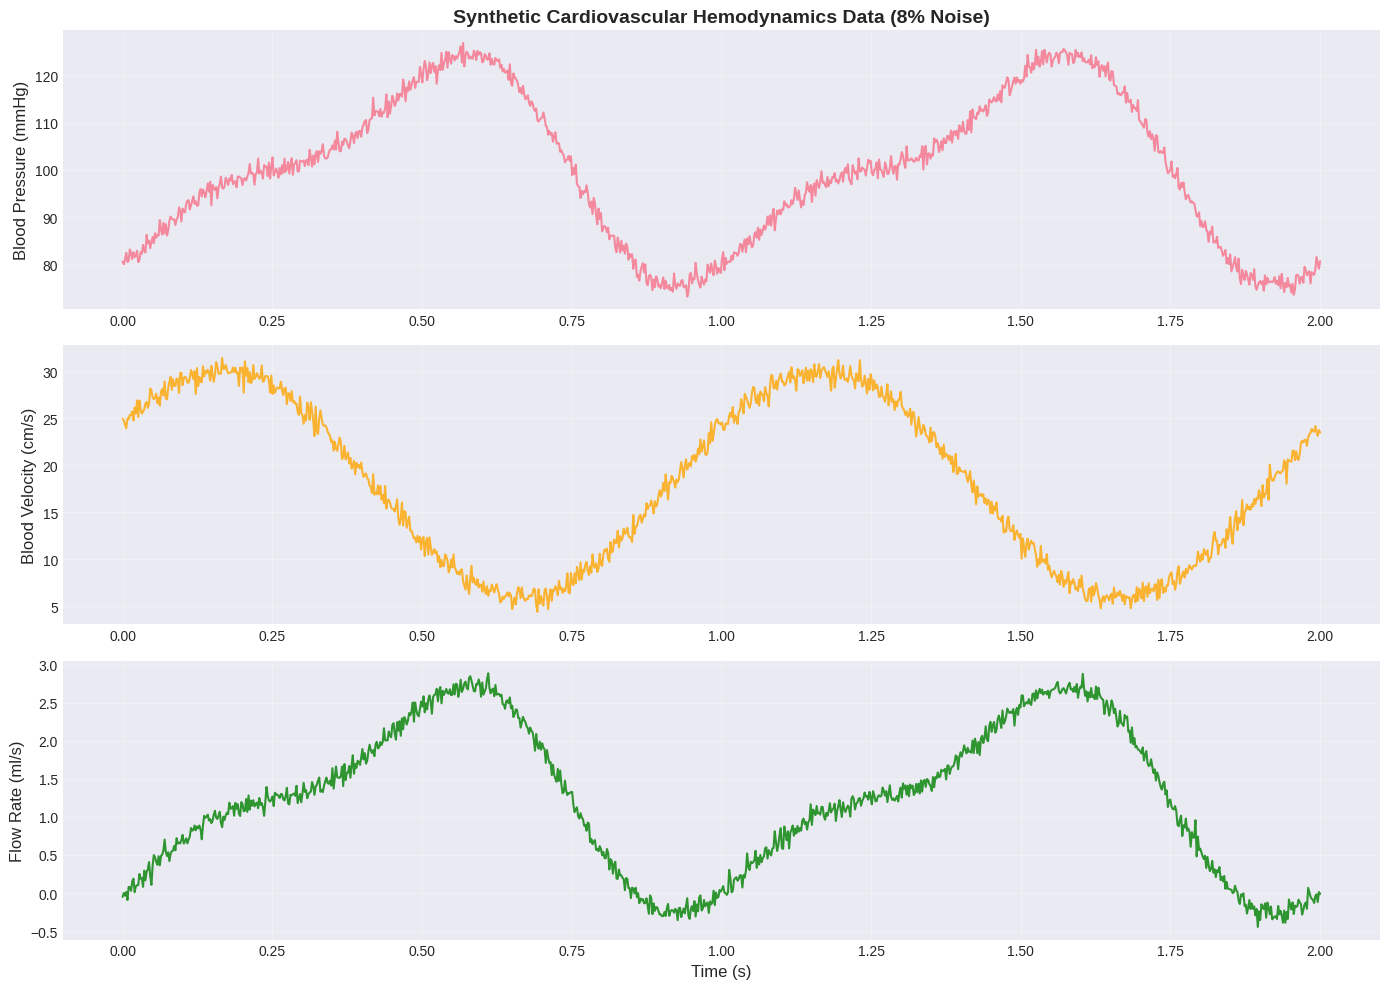


Data statistics:
Pressure: 100.0 ± 15.3 mmHg
Velocity: 18.1 ± 8.5 cm/s
Flow rate: 1.23 ± 0.94 ml/s


In [11]:
def generate_cardiovascular_data(n_samples=1000, noise_level=0.08, cardiac_cycles=2):
    """
    Generate synthetic cardiovascular hemodynamics data

    Args:
        n_samples: Number of time points
        noise_level: Percentage of noise (0.08 = 8%)
        cardiac_cycles: Number of cardiac cycles to simulate

    Returns:
        time, pressure, velocity, flow_rate (all as numpy arrays)
    """
    # Time vector (seconds)
    t = np.linspace(0, cardiac_cycles, n_samples)

    # Physiological parameters
    systolic_pressure = 120  # mmHg
    diastolic_pressure = 80  # mmHg
    heart_rate = 1.0  # Hz (60 bpm)

    # Blood pressure (mmHg) - realistic cardiac waveform
    pressure = diastolic_pressure + \
               (systolic_pressure - diastolic_pressure) * (
                   0.5 * (1 + np.sin(2 * np.pi * heart_rate * t - np.pi/2)) +
                   0.2 * np.sin(4 * np.pi * heart_rate * t)
               )

    # Blood velocity (cm/s) - follows pressure gradient with phase lag
    peak_velocity = 30  # cm/s
    velocity = peak_velocity * (0.6 + 0.4 * np.sin(2 * np.pi * heart_rate * t + np.pi/6))

    # Flow rate (ml/s) - Hagen-Poiseuille relationship
    # Q = (π r⁴ ΔP) / (8 μ L)
    radius = 0.5  # cm (typical artery)
    viscosity = 0.04  # poise (blood viscosity)
    length = 10  # cm (vessel segment)

    delta_p = pressure - diastolic_pressure  # Pressure gradient
    flow_rate = (np.pi * radius**4 * delta_p) / (8 * viscosity * length)

    # Add realistic measurement noise
    if noise_level > 0:
        pressure += np.random.normal(0, noise_level * np.std(pressure), n_samples)
        velocity += np.random.normal(0, noise_level * np.std(velocity), n_samples)
        flow_rate += np.random.normal(0, noise_level * np.std(flow_rate), n_samples)

    return t, pressure, velocity, flow_rate

# Generate training data
print("Generating cardiovascular data...")
t_data, pressure_data, velocity_data, flow_data = generate_cardiovascular_data(
    n_samples=1000,
    noise_level=0.08
)

# Visualize generated data
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

axes[0].plot(t_data, pressure_data, linewidth=1.5, alpha=0.8)
axes[0].set_ylabel('Blood Pressure (mmHg)', fontsize=12)
axes[0].set_title('Synthetic Cardiovascular Hemodynamics Data (8% Noise)', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_data, velocity_data, linewidth=1.5, alpha=0.8, color='orange')
axes[1].set_ylabel('Blood Velocity (cm/s)', fontsize=12)
axes[1].grid(True, alpha=0.3)

axes[2].plot(t_data, flow_data, linewidth=1.5, alpha=0.8, color='green')
axes[2].set_ylabel('Flow Rate (ml/s)', fontsize=12)
axes[2].set_xlabel('Time (s)', fontsize=12)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nData statistics:")
print(f"Pressure: {np.mean(pressure_data):.1f} ± {np.std(pressure_data):.1f} mmHg")
print(f"Velocity: {np.mean(velocity_data):.1f} ± {np.std(velocity_data):.1f} cm/s")
print(f"Flow rate: {np.mean(flow_data):.2f} ± {np.std(flow_data):.2f} ml/s")

## 3. Physics-Informed Loss Function

Combines data-driven loss with physics-based constraints:
- **Data Loss**: MSE between predictions and measurements
- **Physics Loss**: Enforces Hagen-Poiseuille equation and mass conservation

In [12]:
class PhysicsInformedLoss:
    """Combined physics and data loss for PINN training"""

    def __init__(self, lambda_physics=0.5, radius=0.5, viscosity=0.04, length=10):
        """
        Args:
            lambda_physics: Weight for physics loss term
            radius: Vessel radius (cm)
            viscosity: Blood viscosity (poise)
            length: Vessel segment length (cm)
        """
        self.lambda_physics = lambda_physics
        self.radius = radius
        self.viscosity = viscosity
        self.length = length
        self.mse_loss = nn.MSELoss()

    def __call__(self, predictions, targets):
        """
        Calculate total loss

        Args:
            predictions: Model output [batch, 3] (pressure, velocity, flow)
            targets: Ground truth [batch, 3]

        Returns:
            total_loss, data_loss, physics_loss
        """
        # Data loss - MSE on all outputs
        data_loss = self.mse_loss(predictions, targets)

        # Extract predictions
        pressure_pred = predictions[:, 0]
        velocity_pred = predictions[:, 1]
        flow_pred = predictions[:, 2]

        # Physics loss - Hagen-Poiseuille equation
        # Q = (π r⁴ ΔP) / (8 μ L)
        # Assuming baseline pressure = 80 mmHg
        delta_p = pressure_pred - 80.0

        expected_flow = (np.pi * self.radius**4 * delta_p) / \
                       (8 * self.viscosity * self.length)

        physics_loss = self.mse_loss(flow_pred, expected_flow)

        # Continuity equation constraint (optional)
        # For 1D flow: ∂ρ/∂t + ∂(ρv)/∂x = 0
        # Simplified: velocity and flow relationship
        area = np.pi * self.radius**2
        expected_velocity = flow_pred / area
        continuity_loss = torch.mean((velocity_pred - expected_velocity)**2)

        # Total physics loss
        total_physics_loss = physics_loss + 0.1 * continuity_loss

        # Combined loss
        total_loss = data_loss + self.lambda_physics * total_physics_loss

        return total_loss, data_loss, total_physics_loss

# Initialize loss function
criterion = PhysicsInformedLoss(lambda_physics=0.5)
print(" Physics-informed loss function initialized")

 Physics-informed loss function initialized


## 4. Training Loop

In [13]:
def train_pinn(model, train_data, criterion, epochs=1000, lr=0.001, verbose=100):
    """
    Train Physics-Informed Neural Network

    Args:
        model: PINN model
        train_data: Tuple of (inputs, outputs)
        criterion: Physics-informed loss function
        epochs: Number of training epochs
        lr: Learning rate
        verbose: Print frequency

    Returns:
        trained model, training history
    """
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=100, factor=0.5)

    x_train, y_train = train_data
    x_train = torch.FloatTensor(x_train).to(device)
    y_train = torch.FloatTensor(y_train).to(device)

    history = {
        'total_loss': [],
        'data_loss': [],
        'physics_loss': [],
        'epoch': []
    }

    print("\n🏋️  Starting PINN training...\n")
    print(f"{'Epoch':<10} {'Total Loss':<15} {'Data Loss':<15} {'Physics Loss':<15}")
    print("-" * 55)

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        # Forward pass
        predictions = model(x_train)

        # Calculate loss
        total_loss, data_loss, physics_loss = criterion(predictions, y_train)

        # Backward pass
        total_loss.backward()
        optimizer.step()
        scheduler.step(total_loss)

        # Record history
        history['total_loss'].append(total_loss.item())
        history['data_loss'].append(data_loss.item())
        history['physics_loss'].append(physics_loss.item())
        history['epoch'].append(epoch)

        # Print progress
        if (epoch + 1) % verbose == 0 or epoch == 0:
            print(f"{epoch+1:<10} {total_loss.item():<15.6f} {data_loss.item():<15.6f} {physics_loss.item():<15.6f}")

    print("\n Training completed!")
    return model, history

# Prepare training data
position = np.zeros_like(t_data)  # 1D flow, single position
x_train = np.column_stack([t_data, position])
y_train = np.column_stack([pressure_data, velocity_data, flow_data])

print(f"Training data shape: X={x_train.shape}, Y={y_train.shape}")

# Train model
model, history = train_pinn(
    model,
    (x_train, y_train),
    criterion,
    epochs=2000,
    lr=0.001,
    verbose=200
)

Training data shape: X=(1000, 2), Y=(1000, 3)

🏋️  Starting PINN training...

Epoch      Total Loss      Data Loss       Physics Loss   
-------------------------------------------------------
1          3554.410400     3540.491699     27.837223      
200        2058.944824     2045.221924     27.445950      
400        1477.204712     1461.447021     31.515448      
600        1049.098999     1034.546875     29.104174      
800        734.738281      721.352051      26.772503      
1000       509.973358      497.552124      24.842455      
1200       355.035278      343.401794      23.266943      
1400       252.946762      241.946503      22.000530      
1600       189.217712      178.716797      21.001839      
1800       151.880844      141.764633      20.232431      
2000       131.555618      121.727539      19.656153      

 Training completed!


## 5. Visualize Training Progress

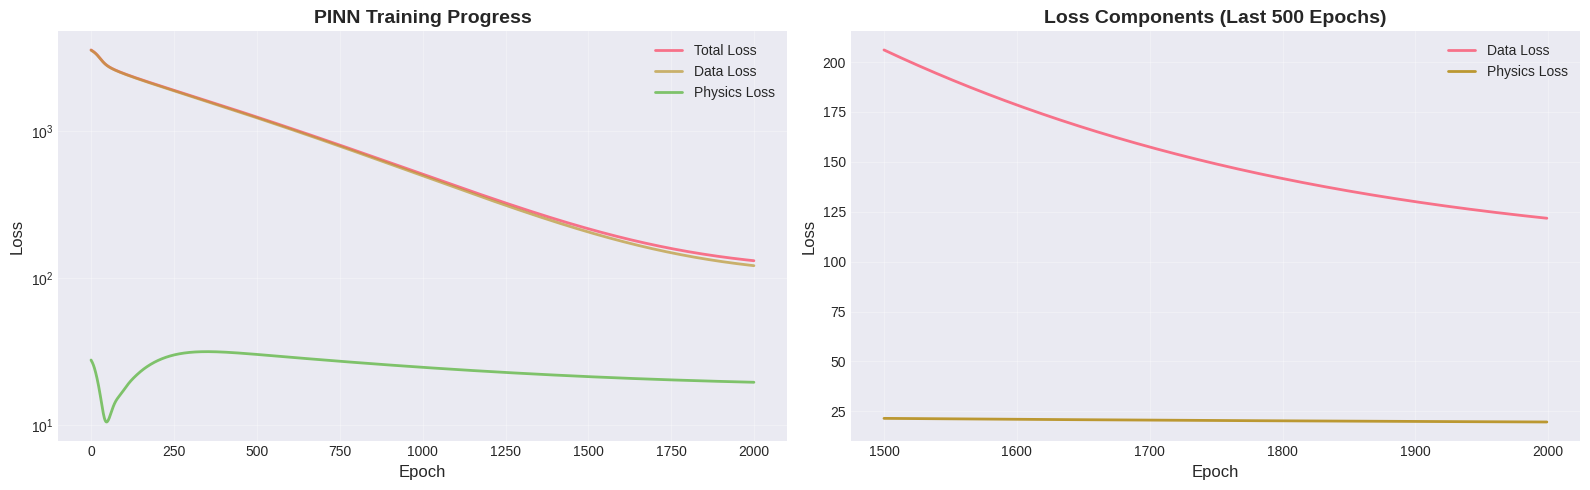


Final losses:
Total Loss: 131.555618
Data Loss: 121.727539
Physics Loss: 19.656153


In [14]:
# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Loss curves
axes[0].plot(history['epoch'], history['total_loss'], label='Total Loss', linewidth=2)
axes[0].plot(history['epoch'], history['data_loss'], label='Data Loss', linewidth=2, alpha=0.7)
axes[0].plot(history['epoch'], history['physics_loss'], label='Physics Loss', linewidth=2, alpha=0.7)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('PINN Training Progress', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].set_yscale('log')
axes[0].grid(True, alpha=0.3)

# Loss components (last 500 epochs)
start_idx = max(0, len(history['epoch']) - 500)
axes[1].plot(history['epoch'][start_idx:], history['data_loss'][start_idx:],
             label='Data Loss', linewidth=2)
axes[1].plot(history['epoch'][start_idx:], history['physics_loss'][start_idx:],
             label='Physics Loss', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Loss', fontsize=12)
axes[1].set_title('Loss Components (Last 500 Epochs)', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nFinal losses:")
print(f"Total Loss: {history['total_loss'][-1]:.6f}")
print(f"Data Loss: {history['data_loss'][-1]:.6f}")
print(f"Physics Loss: {history['physics_loss'][-1]:.6f}")